# Three-level STIRAP with counterdiabatic driving

This notebook simulates population transfer with Gaussian pulses in a three-level $\Lambda$ system.

## STIRAP Hamiltonian

In the ordered basis $(|0\rangle, |C_1\rangle, |T\rangle)$, the Hamiltonian on two-photon resonance is

$$
H_0(t) = \frac{1}{2}
\begin{pmatrix}
0 & g_p\Omega_p(t) & 0 \\
g_p\Omega_p(t) & 2\Delta_1 & g_s\Omega_s(t) \\
0 & g_s\Omega_s(t) & 0
\end{pmatrix}.
$$

The pump pulse $\Omega_p$ couples the initial state $|0\rangle$ to the intermediate state $|C_1\rangle$. The Stokes pulse $\Omega_s$ couples $|C_1\rangle$ to the target state $|T\rangle$. The detuning $\Delta_1$ shifts the intermediate level, and the factors $g_p$ and $g_s$ scale the pump and stokes pulse respectively.

In stimulated Raman adiabatic passage (STIRAP), the Stokes pulse peaks first at $-\tau$ and the pump pulse peaks at $+\tau$. The dark state, proportional to $\Omega_s(t)|0\rangle - \Omega_p(t)|T\rangle$, has zero amplitude in $|C_1\rangle$. As the pulse ratio changes, the dark state connects the initial and target states.

## Counterdiabatic term

Adding $H_{\mathrm{CD}}(t)$ to $H_0(t)$ cancels transitions between its instantaneous eigenstates, so a system prepared in the dark state can follow it even for fast pulses. Differentiate $H_0(t)|n(t)\rangle = E_n(t)|n(t)\rangle$ and project onto $\langle m(t)|$ with $m\ne n$. In units with $\hbar=1$, this gives

$$
\langle m|H_{\mathrm{CD}}|n\rangle
= i\langle m|\dot n\rangle
= i\,\frac{\langle m|\dot H_0|n\rangle}{E_n-E_m},
\qquad m\ne n.
$$

At each time, the code diagonalizes $H_0$ and evaluates $\dot H_0$ from the Gaussian pulse derivatives. It sets the diagonal of $H_{\mathrm{CD}}$ to zero in the instantaneous eigenbasis, skips gaps below $10^{-12}$, and constructs the operator in the original basis.

Run the cells in order with NumPy, SciPy, Matplotlib, and QuTiP installed.

[Berry (2009)](https://doi.org/10.1088/1751-8113/42/36/365303) · [Giannelli and Arimondo (2014)](https://doi.org/10.1103/PhysRevA.89.033419)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qutip import Qobj, basis, sesolve
from scipy.linalg import eigh

In [2]:
e0_3 = basis(3, 0)
ec1_3 = basis(3, 1)
eT_3 = basis(3, 2)

P0_3 = e0_3 * e0_3.dag()
Pc1_3 = ec1_3 * ec1_3.dag()
PT_3 = eT_3 * eT_3.dag()

H0c1_3 = e0_3 * ec1_3.dag() + ec1_3 * e0_3.dag()
Hc1T_3 = ec1_3 * eT_3.dag() + eT_3 * ec1_3.dag()

def Omega_p(t):
    return Omega0 * np.exp(-((t - tau)**2) / (2 * sigma**2))

def Omega_s(t):
    return Omega0 * np.exp(-((t + tau)**2) / (2 * sigma**2))

def dOmega_p(t):
    return Omega_p(t) * (-(t - tau) / sigma**2)

def dOmega_s(t):
    return Omega_s(t) * (-(t + tau) / sigma**2)

def H3_stirap(t):
    return (
        0.5 * g1 * Omega_p(t) * H0c1_3
        + Delta1 * Pc1_3
        + 0.5 * g1 * Omega_s(t) * Hc1T_3
    )

def dH3_stirap(t):
    return (
        0.5 * g1 * dOmega_p(t) * H0c1_3
        + 0.5 * g1 * dOmega_s(t) * Hc1T_3
    )

energy_gaptol = 10**(-12)

def counterdiabatic_term(H, dH, gap_tol=energy_gaptol):
    H = np.array(H.full(), dtype=complex)
    dH = np.array(dH.full(), dtype=complex)

    E, V = eigh(H)
    Hcd = np.zeros_like(H, dtype=complex)

    for n in range(3):
        vn = V[:, n]

        for m in range(3):
            if m == n:
                continue

            vm = V[:, m]
            gap = E[n] - E[m]

            # Skip unresolved gaps near the pulse tails.
            if abs(gap) < gap_tol:
                continue

            elem = np.vdot(vm, dH @ vn) / gap
            Hcd += 1j * elem * np.outer(vm, np.conjugate(vn))

    Hcd = 0.5 * (Hcd + Hcd.conj().T)
    return Qobj(Hcd)

def Hcd3_stirap(t, gap_tol=energy_gaptol):
    return counterdiabatic_term(H3_stirap(t), dH3_stirap(t), gap_tol)

def H3_stirap_total(t, args=None):
    return H3_stirap(t) + Hcd3_stirap(t)

## Population transfer

The dashed and dotted lines mark the pulse centers. The shaded interval appears when the target population reaches both thresholds, $P_T=\epsilon_t$ and $P_T=1-\epsilon_t$, in the standard STIRAP run.

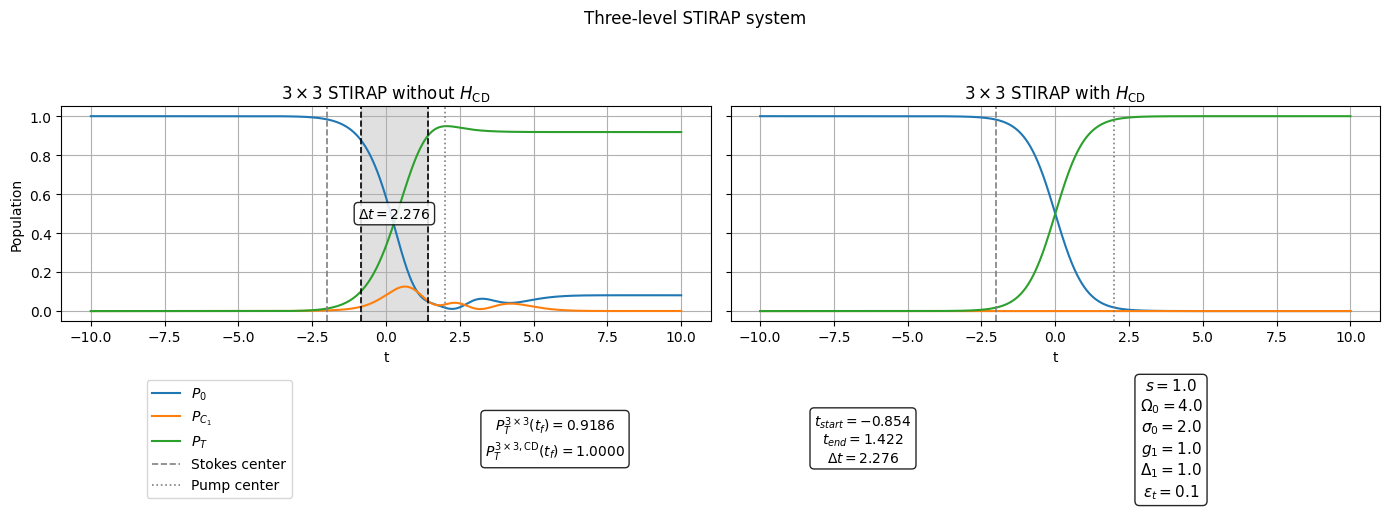

Final population in |T> for 3x3 STIRAP without Hcd: 0.9186
Final population in |T> for 3x3 STIRAP with Hcd: 1.0000
Transition interval for 3x3 STIRAP without Hcd: [-0.8539, 1.4220], duration = 2.2760


In [3]:
def crossing_time(tlist, y, level):
    idx = np.where((y[:-1] - level) * (y[1:] - level) <= 0)[0]

    if len(idx) == 0:
        return None

    i = idx[0]
    t1, t2 = tlist[i], tlist[i + 1]
    y1, y2 = y[i], y[i + 1]

    return t1 + (level - y1) * (t2 - t1) / (y2 - y1)

def transition_interval(tlist, pT, eps=0.05):
    t_start = crossing_time(tlist, pT, eps)
    t_end = crossing_time(tlist, pT, 1 - eps)

    if t_start is None or t_end is None:
        return None, None, None

    return t_start, t_end, t_end - t_start

def run_3level_stirap_system():
    result_3_stirap = sesolve(H3_stirap, e0_3, tlist, e_ops=[P0_3, Pc1_3, PT_3])
    p0_3, pc1_3, pT_3 = result_3_stirap.expect

    result_3_stirap_cd = sesolve(H3_stirap_total, e0_3, tlist, e_ops=[P0_3, Pc1_3, PT_3])
    p0_3_cd, pc1_3_cd, pT_3_cd = result_3_stirap_cd.expect

    t_start, t_end, duration = transition_interval(tlist, pT_3, eps=epst)

    param_text = "\n".join([
        rf"$s = {s}$",
        rf"$\Omega_0 = {Omega0}$",
        rf"$\sigma_0 = {sigma0}$",
        rf"$g_1 = {g1}$",
        rf"$\Delta_1 = {Delta1}$",
        rf"$\epsilon_t = {epst}$"
    ])

    final_text = "\n".join([
        rf"$P_T^{{3\times3}}(t_f) = {pT_3[-1]:.4f}$",
        rf"$P_T^{{3\times3,\mathrm{{CD}}}}(t_f) = {pT_3_cd[-1]:.4f}$"
    ])

    interval_text = (
        rf"$t_{{start}} = {t_start:.3f}$" + "\n" +
        rf"$t_{{end}} = {t_end:.3f}$" + "\n" +
        rf"$\Delta t = {duration:.3f}$"
        if duration is not None
        else "Transition interval not found"
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

    datasets = [
        (axes[0], p0_3, pc1_3, pT_3, r"$3\times3$ STIRAP without $H_{\mathrm{CD}}$"),
        (axes[1], p0_3_cd, pc1_3_cd, pT_3_cd, r"$3\times3$ STIRAP with $H_{\mathrm{CD}}$")
    ]

    for ax, P0_data, Pc1_data, PT_data, title in datasets:
        ax.plot(tlist, P0_data, label=r"$P_0$")
        ax.plot(tlist, Pc1_data, label=r"$P_{C_1}$")
        ax.plot(tlist, PT_data, label=r"$P_T$")
        ax.axvline(-tau, color="gray", linestyle="--", linewidth=1.2, label=r"Stokes center")
        ax.axvline(tau, color="gray", linestyle=":", linewidth=1.2, label=r"Pump center")
        ax.set_title(title)
        ax.set_xlabel("t")
        ax.set_ylim(-0.05, 1.05)
        ax.grid(True)

    if t_start is not None and t_end is not None:
        axes[0].axvline(t_start, linestyle="--", color="black", linewidth=1.2)
        axes[0].axvline(t_end, linestyle="--", color="black", linewidth=1.2)
        axes[0].axvspan(t_start, t_end, color="black", alpha=0.12)

        axes[0].text(
            0.5 * (t_start + t_end),
            0.5,
            rf"$\Delta t = {duration:.3f}$",
            ha="center",
            va="center",
            fontsize=10,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
        )

    axes[0].set_ylabel("Population")

    handles, labels_plot = axes[0].get_legend_handles_labels()

    fig.legend(
        handles, labels_plot,
        loc="center",
        bbox_to_anchor=(0.16, box_y),
        ncol=1,
        frameon=True
    )

    fig.text(
        0.40, box_y, final_text,
        ha="center",
        va="center",
        fontsize=10,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
    )

    fig.text(
        0.62, box_y, interval_text,
        ha="center",
        va="center",
        fontsize=10,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
    )

    fig.text(
        0.84, box_y, param_text,
        ha="center",
        va="center",
        fontsize=11,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
    )

    fig.suptitle("Three-level STIRAP system")
    fig.tight_layout(rect=[0, 0.24, 1, 0.93])

    plt.show()

    print(f"Final population in |T> for 3x3 STIRAP without Hcd: {pT_3[-1]:.4f}")
    print(f"Final population in |T> for 3x3 STIRAP with Hcd: {pT_3_cd[-1]:.4f}")

    if duration is not None:
        print(f"Transition interval for 3x3 STIRAP without Hcd: [{t_start:.4f}, {t_end:.4f}], duration = {duration:.4f}")
    else:
        print("Transition interval for 3x3 STIRAP without Hcd: not found")

    return result_3_stirap, result_3_stirap_cd


s = 1.0
T = 10.0

Delta1 = 1.0

Omega0 = 4.0
g1 = 1.0

sigma0 = 2.0
tau0 = 2.0

sigma = s * sigma0
tau = s * tau0

tlist = np.linspace(-s * T, s * T, 2000)

epst = 0.1
box_y = 0.12

result_3_stirap, result_3_stirap_cd = run_3level_stirap_system()

## Instantaneous spectrum

Alternating colors mark eigenvalue branches of $H_0(t)$ that are visually indistinguishable on this scale.

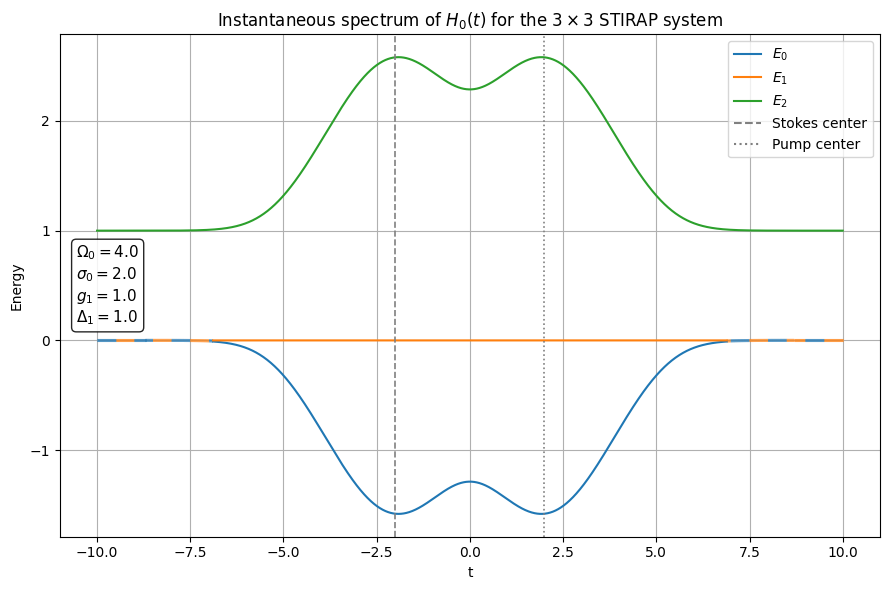

In [4]:
def plot_spectrum_with_overlap_dashes(ax, tlist, evals, labels, colors, overlap_tol=1e-2, dash_dt=0.5, linewidth=2.2):
    n_levels = evals.shape[1]
    already_overlap = np.zeros((len(tlist) - 1, n_levels), dtype=bool)

    for i in range(len(tlist) - 1):
        y_mid = 0.5 * (evals[i] + evals[i + 1])

        groups = []
        used = set()

        for n in range(n_levels):
            if n in used:
                continue

            group = [m for m in range(n_levels) if abs(y_mid[m] - y_mid[n]) < overlap_tol]

            if len(group) > 1:
                groups.append(group)
                used.update(group)

        # Alternate colors when branches overlap on a segment.
        for group in groups:
            y_seg = np.mean(evals[i:i + 2, group], axis=1)

            t_mid = 0.5 * (tlist[i] + tlist[i + 1])
            color_index = int((t_mid - tlist[0]) / dash_dt) % len(group)
            level_index = group[color_index]

            ax.plot(
                tlist[i:i + 2],
                y_seg,
                color=colors[level_index],
                linewidth=linewidth,
                solid_capstyle="butt"
            )

            for n in group:
                already_overlap[i, n] = True

    for n in range(n_levels):
        start = None

        for i in range(len(tlist) - 1):
            if not already_overlap[i, n]:
                if start is None:
                    start = i
            else:
                if start is not None:
                    ax.plot(
                        tlist[start:i + 1],
                        evals[start:i + 1, n],
                        color=colors[n],
                        linewidth=1.5
                    )
                    start = None

        if start is not None:
            ax.plot(
                tlist[start:],
                evals[start:, n],
                color=colors[n],
                linewidth=1.5
            )

evals_3_stirap = np.array([H3_stirap(t).eigenenergies() for t in tlist])

y_min = np.min(evals_3_stirap)
y_max = np.max(evals_3_stirap)
y_pad = 0.05 * (y_max - y_min)
ylim = (y_min - y_pad, y_max + y_pad)

labels = [r"$E_0$", r"$E_1$", r"$E_2$"]
colors = ["tab:blue", "tab:orange", "tab:green"]

param_text = "\n".join([
    rf"$\Omega_0 = {Omega0}$",
    rf"$\sigma_0 = {sigma0}$",
    rf"$g_1 = {g1}$",
    rf"$\Delta_1 = {Delta1}$"
])

fig, ax = plt.subplots(figsize=(9, 6))

plot_spectrum_with_overlap_dashes(
    ax,
    tlist,
    evals_3_stirap,
    labels,
    colors,
    overlap_tol=1e-2,
    dash_dt=0.5,
    linewidth=2.2
)

ax.axvline(-tau, color="gray", linestyle="--", linewidth=1.2, label=r"Stokes center")
ax.axvline(tau, color="gray", linestyle=":", linewidth=1.2, label=r"Pump center")

ax.text(
    0.02,
    0.5,
    param_text,
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="center",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
)

ax.set_title(r"Instantaneous spectrum of $H_0(t)$ for the $3\times3$ STIRAP system")
ax.set_xlabel("t")
ax.set_ylabel("Energy")
ax.set_ylim(ylim)
ax.grid(True)

handles = [
    plt.Line2D([0], [0], color=colors[n], label=labels[n])
    for n in range(len(labels))
]

handles += [
    plt.Line2D([0], [0], color="gray", linestyle="--", label=r"Stokes center"),
    plt.Line2D([0], [0], color="gray", linestyle=":", label=r"Pump center")
]

ax.legend(handles=handles)

plt.tight_layout()

plt.show()

## Pulse duration scan

The factor $s$ scales the pulse widths, pulse centers, and simulation window together. Since $H_0^{(s)}(t)=H_0^{(1)}(t/s)$, the CD term scales as $H_{\mathrm{CD}}^{(s)}(t)=1/s H_{\mathrm{CD}}^{(1)}(t/s)$. The scan interpolates the CD term computed on the reference grid.

The plot uses $10^{-14}$ as a floor for the log axis. Very small values of $1-P_T(t_f)$ are sensitive to the finite pulse window, interpolation, and solver tolerances.

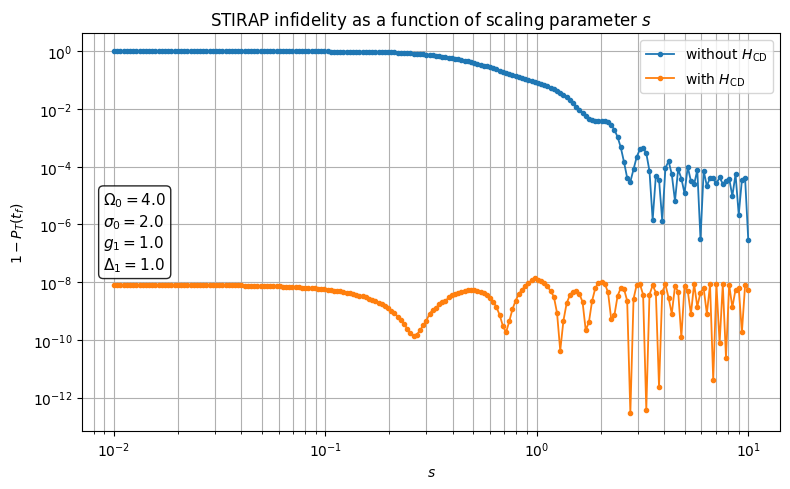

Best without Hcd: s = 10.0000, infidelity = 2.8050e-07
Best with Hcd:    s = 2.7683, infidelity = 2.8955e-13


In [5]:
s_vals = np.logspace(-2, 1, 200)

n_eval_scan = 800

Omega_ref = Omega0
sigma_ref = sigma0
tau_ref = tau0
Delta_ref = Delta1
g_ref = g1
T_ref = T

tau_cd = np.linspace(-T_ref, T_ref, n_eval_scan)

def Omega_p_ref(t):
    return Omega_ref * np.exp(-((t - tau_ref)**2) / (2 * sigma_ref**2))

def Omega_s_ref(t):
    return Omega_ref * np.exp(-((t + tau_ref)**2) / (2 * sigma_ref**2))

def dOmega_p_ref(t):
    return Omega_p_ref(t) * (-(t - tau_ref) / sigma_ref**2)

def dOmega_s_ref(t):
    return Omega_s_ref(t) * (-(t + tau_ref) / sigma_ref**2)

def H3_stirap_ref(t):
    return (
        0.5 * g_ref * Omega_p_ref(t) * H0c1_3
        + Delta_ref * Pc1_3
        + 0.5 * g_ref * Omega_s_ref(t) * Hc1T_3
    )

def dH3_stirap_ref(t):
    return (
        0.5 * g_ref * dOmega_p_ref(t) * H0c1_3
        + 0.5 * g_ref * dOmega_s_ref(t) * Hc1T_3
    )

def Hcd3_stirap_ref(t, gap_tol=energy_gaptol):
    return counterdiabatic_term(H3_stirap_ref(t), dH3_stirap_ref(t), gap_tol)

Hcd_base_list = [Hcd3_stirap_ref(t) for t in tau_cd]

def H3_stirap_scaled(t, s):
    tau_scaled = t / s

    Op = Omega_ref * np.exp(-((tau_scaled - tau_ref)**2) / (2 * sigma_ref**2))
    Os = Omega_ref * np.exp(-((tau_scaled + tau_ref)**2) / (2 * sigma_ref**2))

    return (
        0.5 * g_ref * Op * H0c1_3
        + Delta_ref * Pc1_3
        + 0.5 * g_ref * Os * Hc1T_3
    )

def Hcd3_stirap_scaled(t, s):
    tau_scaled = t / s

    if tau_scaled <= tau_cd[0]:
        return Hcd_base_list[0] / s

    if tau_scaled >= tau_cd[-1]:
        return Hcd_base_list[-1] / s

    idx = np.searchsorted(tau_cd, tau_scaled)

    tau_left = tau_cd[idx - 1]
    tau_right = tau_cd[idx]

    w = (tau_scaled - tau_left) / (tau_right - tau_left)

    return ((1 - w) * Hcd_base_list[idx - 1] + w * Hcd_base_list[idx]) / s

P_T_end_stirap = np.zeros(len(s_vals))
P_T_end_stirap_cd = np.zeros(len(s_vals))

for i, s_scan in enumerate(s_vals):
    tlist_scan = np.linspace(-s_scan * T_ref, s_scan * T_ref, n_eval_scan)

    def H_no_cd(t, args):
        return H3_stirap_scaled(t, s_scan)

    def H_with_cd(t, args):
        return H3_stirap_scaled(t, s_scan) + Hcd3_stirap_scaled(t, s_scan)

    result_scan = sesolve(H_no_cd, e0_3, tlist_scan, e_ops=[PT_3])
    result_scan_cd = sesolve(H_with_cd, e0_3, tlist_scan, e_ops=[PT_3])

    P_T_end_stirap[i] = result_scan.expect[0][-1]
    P_T_end_stirap_cd[i] = result_scan_cd.expect[0][-1]

infidelity_stirap = np.maximum(1 - P_T_end_stirap, 1e-14)
infidelity_stirap_cd = np.maximum(1 - P_T_end_stirap_cd, 1e-14)

fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(s_vals, infidelity_stirap, marker="o", markersize=3, linewidth=1.3, label=r"without $H_{\mathrm{CD}}$")
ax.loglog(s_vals, infidelity_stirap_cd, marker="o", markersize=3, linewidth=1.3, label=r"with $H_{\mathrm{CD}}$")

param_text = "\n".join([
    rf"$\Omega_0 = {Omega_ref}$",
    rf"$\sigma_0 = {sigma_ref}$",
    rf"$g_1 = {g_ref}$",
    rf"$\Delta_1 = {Delta_ref}$"
])

ax.text(
    0.03,
    0.5,
    param_text,
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="center",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
)

ax.set_title(r"STIRAP infidelity as a function of scaling parameter $s$")
ax.set_xlabel(r"$s$")
ax.set_ylabel(r"$1 - P_T(t_f)$")
ax.grid(True, which="both")
ax.legend()

plt.tight_layout()

plt.show()

print(f"Best without Hcd: s = {s_vals[np.argmin(infidelity_stirap)]:.4f}, infidelity = {np.min(infidelity_stirap):.4e}")
print(f"Best with Hcd:    s = {s_vals[np.argmin(infidelity_stirap_cd)]:.4f}, infidelity = {np.min(infidelity_stirap_cd):.4e}")